# Multi-Objective Regularized Evolution — Two Variants

Runs two variants of MO-RE on every **dataset × hardware platform** combination  
and compares each Pareto front against the exhaustive (true) front.

| Variant | Description |
|---|---|
| **MO-RE** | Base: aging evolution + Pareto parent selection |
| **MO-RE+Archive** | Adds an external Pareto archive — parents sampled from population (explore) **and** archive (exploit) |

**Why the archive matters**:  
In standard aging evolution, strong architectures can be lost when they age out of the population.  
The archive stores every non-dominated solution ever found and never discards them.  
Parent selection draws from both the aging population (diversity) and the archive (quality),  
preventing the search from forgetting good tradeoffs.

## 0 · Configuration

In [1]:
import numpy as np

# ── Paths ─────────────────────────────────────────────────────────────────────
HW_NAS_ROOT   = "/kaggle/input/datasets/djouaheryasmine/hw-nas-bench-main/HW-NAS-Bench-main"
HW_NAS_PICKLE = f"{HW_NAS_ROOT}/HW-NAS-Bench-v1_0.pickle"
NAS201_ROOT   = "/kaggle/input/datasets/djouaheryasmine/nas-bench-201/NAS-Bench-201"
ACC_CSV       = "/kaggle/input/datasets/djouaheryasmine/nasbench201-accuracies/nasbench201_accuracies.csv"
EXHAUSTIVE_ROOT = "/kaggle/input/datasets/djouaheryasmine/results/Results"
OUTPUT_ROOT     = "/kaggle/working/mo_re_results"

# ── Search grid ───────────────────────────────────────────────────────────────
DATASETS   = ["cifar10", "cifar100", "ImageNet16-120"]
PLATFORMS  = ["edgegpu", "raspi4", "pixel3", "fpga"]

# ── Evolution hyper-parameters ────────────────────────────────────────────────
POPULATION_SIZE = 50
NUM_CYCLES      = 200  
TOURNAMENT_SIZE = 10
NUM_RUNS        = 5
SEED            = 42

# Archive variant: probability of sampling parent from archive vs. population
# 0.0 = always population (= base MO-RE), 1.0 = always archive
ARCHIVE_SAMPLE_PROB = 0.4   # 30% of parents come from the archive

SEARCH_SPACE_SIZE = 15_625
np.random.seed(SEED)

print(f"Grid    : {len(DATASETS)} datasets × {len(PLATFORMS)} platforms = {len(DATASETS)*len(PLATFORMS)} combinations")
print(f"Variants: MO-RE | MO-RE+Archive")
print(f"Budget  : P={POPULATION_SIZE}, S={TOURNAMENT_SIZE}, C={NUM_CYCLES}, {NUM_RUNS} runs each")
print(f"Archive : parent drawn from archive with prob={ARCHIVE_SAMPLE_PROB}")

Grid    : 3 datasets × 4 platforms = 12 combinations
Variants: MO-RE | MO-RE+Archive
Budget  : P=50, S=10, C=200, 5 runs each
Archive : parent drawn from archive with prob=0.4


## 1 · Imports & benchmark loading

In [2]:
import sys, os, collections
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, HW_NAS_ROOT)
sys.path.insert(0, NAS201_ROOT)

from hw_nas_bench_api import HWNASBenchAPI as HWAPI

hw_api = HWAPI(HW_NAS_PICKLE, search_space="nasbench201")
acc_df = pd.read_csv(ACC_CSV).set_index("arch_index")

os.makedirs(OUTPUT_ROOT, exist_ok=True)
print("Benchmarks loaded.")

Benchmarks loaded.


## 2 · Core functions

Oracle, mutation, Pareto utilities, archive management, and metrics.

In [3]:
# ── Oracle ────────────────────────────────────────────────────────────────────

def evaluate(arch_index: int, dataset: str, latency_key: str) -> dict:
    """Return accuracy and latency for one architecture (lookup only)."""
    return {
        "arch_index" : arch_index,
        "accuracy"   : float(acc_df.loc[arch_index, f"acc_{dataset}"]),
        "latency"    : float(hw_api.query_by_index(arch_index, dataset)[latency_key]),
    }


# ── Mutation ──────────────────────────────────────────────────────────────────

def mutate(arch_index: int, rng: np.random.Generator) -> int:
    """Sample a different architecture index at random."""
    child = arch_index
    while child == arch_index:
        child = int(rng.integers(0, SEARCH_SPACE_SIZE))
    return child


# ── Pareto utilities ──────────────────────────────────────────────────────────

def dominates(a: dict, b: dict) -> bool:
    """True if a dominates b (maximize accuracy, minimize latency)."""
    return (
        a["accuracy"] >= b["accuracy"] and
        a["latency"]  <= b["latency"]  and
        (a["accuracy"] > b["accuracy"] or a["latency"] < b["latency"])
    )


def select_pareto_best(sample: list) -> dict:
    """
    From a sample, return the non-dominated model.
    Tiebreak: highest accuracy.
    """
    non_dominated = [
        c for c in sample
        if not any(dominates(o, c) for o in sample if o is not c)
    ]
    return max(non_dominated, key=lambda m: m["accuracy"])


def compute_pareto_front(models: list) -> list:
    """Return the non-dominated subset of a list of models."""
    return [
        m for m in models
        if not any(dominates(o, m) for o in models if o is not m)
    ]


def to_array(front: list) -> np.ndarray:
    """Convert list of dicts to (N, 2) array: [accuracy, latency]."""
    return np.array([[m["accuracy"], m["latency"]] for m in front])


# ── Archive management ────────────────────────────────────────────────────────

def update_archive(archive: list, new_model: dict) -> list:
    """
    Add new_model to the archive if it is not dominated by any current member.
    Remove any archive members that are dominated by new_model.
    The archive only grows in quality — nothing is ever removed by age.

    Returns the updated archive.
    """
    # If new model is dominated by anyone already in archive, discard it
    if any(dominates(member, new_model) for member in archive):
        return archive

    # Remove archive members that new model dominates
    archive = [m for m in archive if not dominates(new_model, m)]

    # Add new model
    archive.append(new_model)
    return archive


# ── Comparison metrics ────────────────────────────────────────────────────────

def hypervolume_2d(front_arr: np.ndarray, ref_point: tuple) -> float:
    """2D hypervolume (maximize accuracy, minimize latency)."""
    pts = np.column_stack([-front_arr[:, 0], front_arr[:, 1]])
    ref = np.array([-ref_point[0], ref_point[1]])
    pts = pts[np.argsort(pts[:, 0])]
    hv, prev_y = 0.0, ref[1]
    for pt in pts:
        if pt[1] < prev_y:
            hv += (ref[0] - pt[0]) * (prev_y - pt[1])
            prev_y = pt[1]
    return hv


def normalize(arr, vmin, vmax):
    return (arr - vmin) / (vmax - vmin + 1e-8)


def compute_metrics(approx_front: list, true_front: list) -> dict:
    """Compute HV ratio, GD, IGD between approximated and true Pareto fronts."""
    approx_arr = to_array(approx_front)
    true_arr   = to_array(true_front)

    all_acc = np.concatenate([approx_arr[:, 0], true_arr[:, 0]])
    all_lat = np.concatenate([approx_arr[:, 1], true_arr[:, 1]])
    ref     = (np.min(all_acc) - 1.0, np.max(all_lat) + 1.0)

    hv_true   = hypervolume_2d(true_arr,   ref)
    hv_approx = hypervolume_2d(approx_arr, ref)

    vmin = np.array([np.min(all_acc), np.min(all_lat)])
    vmax = np.array([np.max(all_acc), np.max(all_lat)])
    an   = normalize(approx_arr, vmin, vmax)
    tn   = normalize(true_arr,   vmin, vmax)

    gd_val  = float(np.mean([np.min(np.linalg.norm(tn - pt, axis=1)) for pt in an]))
    igd_val = float(np.mean([np.min(np.linalg.norm(an - pt, axis=1)) for pt in tn]))

    return {
        "hv_ratio"          : hv_approx / hv_true * 100 if hv_true > 0 else 0.0,
        "gd"                : gd_val,
        "igd"               : igd_val,
        "front_size_true"   : len(true_front),
        "front_size_approx" : len(approx_front),
    }


print("All core functions defined.")

All core functions defined.


## 3 · Evolution algorithms

### Variant 1 — MO-RE (base)
Identical to the version in `mo-re.ipynb`. Included here unchanged as the baseline.

### Variant 2 — MO-RE+Archive
Adds three things to the base algorithm:
1. An **external Pareto archive** that stores every non-dominated model ever seen
2. After each evaluation the archive is **updated** (new model added, dominated members removed)
3. At parent selection time, with probability `ARCHIVE_SAMPLE_PROB`, the tournament is sampled from the **archive** instead of the population — this is the exploitation step

Everything else (aging, mutation, Pareto selection rule) is **unchanged**.

In [4]:
# ── Variant 1: MO-RE (base) — unchanged from mo-re.ipynb ─────────────────────

def run_mo_re(dataset: str, latency_key: str, seed: int) -> list:
    """
    Base Multi-Objective Regularized Evolution.
    - Aging population (kill oldest)
    - Pareto-based parent selection
    Returns full history of evaluated models.
    """
    rng        = np.random.default_rng(seed)
    population = collections.deque()
    history    = []

    # Phase 1: random initialisation
    while len(population) < POPULATION_SIZE:
        m = evaluate(int(rng.integers(0, SEARCH_SPACE_SIZE)), dataset, latency_key)
        population.append(m)
        history.append(m)

    # Phase 2: evolution
    for _ in range(NUM_CYCLES):
        pop    = list(population)
        sample = [pop[i] for i in rng.integers(0, len(pop), size=TOURNAMENT_SIZE)]
        parent = select_pareto_best(sample)
        child  = evaluate(mutate(parent["arch_index"], rng), dataset, latency_key)
        population.append(child)
        history.append(child)
        population.popleft()   # kill oldest — aging

    return history


# ── Variant 2: MO-RE+Archive ──────────────────────────────────────────────────

def run_mo_re_archive(dataset: str, latency_key: str, seed: int) -> tuple:
    """
    MO-RE with an external Pareto archive.

    Changes vs. base MO-RE (everything else is identical):
      1. archive is maintained in parallel with the population
      2. archive is updated after every evaluation
      3. with prob ARCHIVE_SAMPLE_PROB, the tournament sample is drawn
         from the archive instead of the population
         → exploitation: parents come from the best solutions ever found
         → the aging population still provides exploration

    Returns (history, archive) so the final archive can be inspected
    independently from the full history.
    """
    rng        = np.random.default_rng(seed)
    population = collections.deque()
    history    = []
    archive    = []           # ← external Pareto archive, never ages out

    # Phase 1: random initialisation
    while len(population) < POPULATION_SIZE:
        m = evaluate(int(rng.integers(0, SEARCH_SPACE_SIZE)), dataset, latency_key)
        population.append(m)
        history.append(m)
        archive = update_archive(archive, m)   # ← archive updated from the start

    # Phase 2: evolution
    for _ in range(NUM_CYCLES):

        # ── Parent selection: population (explore) or archive (exploit) ───────
        if len(archive) >= TOURNAMENT_SIZE and rng.random() < ARCHIVE_SAMPLE_PROB:
            # Sample tournament from archive
            indices = rng.integers(0, len(archive), size=TOURNAMENT_SIZE)
            sample  = [archive[i] for i in indices]
        else:
            # Sample tournament from aging population (base behaviour)
            pop     = list(population)
            indices = rng.integers(0, len(pop), size=TOURNAMENT_SIZE)
            sample  = [pop[i] for i in indices]

        parent = select_pareto_best(sample)    # same selection rule as base

        # ── Mutate, evaluate, update ──────────────────────────────────────────
        child = evaluate(mutate(parent["arch_index"], rng), dataset, latency_key)

        population.append(child)
        history.append(child)
        population.popleft()                   # kill oldest — aging unchanged

        archive = update_archive(archive, child)   # ← keep archive current

    return history, archive


print("Both variant functions defined.")

Both variant functions defined.


## 4 · Plot helper

In [5]:
def plot_comparison(true_front, results, dataset, platform, save_path):
    """
    Two-panel figure:
      Left  — scatter of evaluated models + both Pareto fronts overlaid
      Right — side-by-side metric bars for both variants

    results = {
        "MO-RE"         : {"front": [...], "history": [...], "metrics": {...}},
        "MO-RE+Archive" : {"front": [...], "history": [...], "metrics": {...},
                           "archive": [...]},
    }
    """
    STYLES = {
        "MO-RE"         : {"color": "steelblue",  "ls": "-",  "marker": "o"},
        "MO-RE+Archive" : {"color": "darkorange", "ls": "--", "marker": "s"},
    }

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle(f"{dataset} / {platform}", fontsize=13, fontweight="bold")

    # Background scatter — MO-RE evaluated models
    base_hist = results["MO-RE"]["history"]
    ax1.scatter(
        [m["latency"]  for m in base_hist],
        [m["accuracy"] for m in base_hist],
        s=6, alpha=0.15, color="gray", zorder=1, label="Evaluated (MO-RE)"
    )

    # True Pareto front
    true_arr = to_array(true_front)
    true_s   = true_arr[np.argsort(true_arr[:, 1])]
    ax1.plot(true_s[:, 1], true_s[:, 0],
             "k-", lw=2.5, ms=6, marker="x", zorder=5,
             label=f"True front ({len(true_front)} pts)")

    # Each variant front
    for name, res in results.items():
        arr = to_array(res["front"])
        s   = arr[np.argsort(arr[:, 1])]
        st  = STYLES[name]
        ax1.plot(s[:, 1], s[:, 0],
                 color=st["color"], ls=st["ls"], marker=st["marker"],
                 lw=1.8, ms=5, zorder=4,
                 label=f"{name} ({len(res['front'])} pts)")

    ax1.set_xlabel("Latency (ms)")
    ax1.set_ylabel("Accuracy (%)")
    ax1.set_title("Pareto fronts")
    ax1.legend(fontsize=8)

    # Metric bars
    metric_keys   = ["hv_ratio", "gd", "igd"]
    metric_labels = ["HV ratio (%)", "GD (×100)", "IGD (×100)"]
    multipliers   = [1.0, 100.0, 100.0]
    x      = np.arange(len(metric_keys))
    width  = 0.35

    for i, (name, res) in enumerate(results.items()):
        vals   = [res["metrics"][k] * multipliers[j] for j, k in enumerate(metric_keys)]
        offset = (i - 0.5) * width
        bars   = ax2.bar(x + offset, vals, width,
                         color=STYLES[name]["color"], label=name, alpha=0.85)
        for bar, val in zip(bars, vals):
            ax2.text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + 0.3,
                     f"{val:.2f}", ha="center", va="bottom", fontsize=9)

    ax2.set_xticks(x)
    ax2.set_xticklabels(metric_labels)
    ax2.set_title("Quality metrics (HV↑  GD↓  IGD↓)")
    ax2.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.close()


print("Plot helper defined.")

Plot helper defined.


## 5 · Main loop — all dataset × platform combinations

In [6]:
summary_rows = []
total = len(DATASETS) * len(PLATFORMS)
done  = 0

for dataset in DATASETS:
    for platform in PLATFORMS:
        done += 1
        latency_key = f"{platform}_latency"
        print(f"\n[{done:>2}/{total}]  {dataset} / {platform}")
        print("   " + "-" * 45)

        # ── Load true (exhaustive) Pareto front ───────────────────────────────
        true_csv = os.path.join(
            EXHAUSTIVE_ROOT, dataset, platform, "pareto_front.csv"
        )
        if not os.path.exists(true_csv):
            print(f"   WARNING: {true_csv} not found — skipping.")
            continue
        true_front = pd.read_csv(true_csv)[["accuracy", "latency"]].to_dict("records")

        # ── Run both variants ─────────────────────────────────────────────────
        results = {}

        # Variant 1: MO-RE (base)
        base_histories = [run_mo_re(dataset, latency_key, SEED + r) for r in range(NUM_RUNS)]
        base_models    = [m for h in base_histories for m in h]
        base_front     = compute_pareto_front(base_models)
        results["MO-RE"] = {
            "front"   : base_front,
            "history" : base_models,
            "metrics" : compute_metrics(base_front, true_front),
        }

        # Variant 2: MO-RE+Archive
        arch_histories, arch_archives = [], []
        for r in range(NUM_RUNS):
            h, a = run_mo_re_archive(dataset, latency_key, SEED + r)
            arch_histories.append(h)
            arch_archives.append(a)

        # Aggregate: merge all per-run archives into one global archive
        global_archive = []
        for a in arch_archives:
            for m in a:
                global_archive = update_archive(global_archive, m)

        arch_models = [m for h in arch_histories for m in h]
        results["MO-RE+Archive"] = {
            "front"   : global_archive,     # archive IS the final front
            "history" : arch_models,
            "metrics" : compute_metrics(global_archive, true_front),
            "archive" : global_archive,
        }

        # ── Print results ─────────────────────────────────────────────────────
        for name, res in results.items():
            m = res["metrics"]
            print(f"   {name:<20}  "
                  f"HV: {m['hv_ratio']:>5.1f}%  "
                  f"GD: {m['gd']:.4f}  "
                  f"IGD: {m['igd']:.4f}  "
                  f"front: {m['front_size_approx']} pts")

        # ── Save outputs ──────────────────────────────────────────────────────
        out_dir = os.path.join(OUTPUT_ROOT, dataset, dataset, platform)
        os.makedirs(out_dir, exist_ok=True)

        pd.DataFrame(results["MO-RE"]["front"]).to_csv(
            os.path.join(out_dir, "mo_re_front.csv"), index=False
        )
        pd.DataFrame(results["MO-RE+Archive"]["archive"]).to_csv(
            os.path.join(out_dir, "mo_re_archive_front.csv"), index=False
        )
        plot_comparison(
            true_front, results, dataset, platform,
            os.path.join(out_dir, "comparison.png")
        )

        # ── Accumulate summary ────────────────────────────────────────────────
        row = {"dataset": dataset, "platform": platform}
        for name, res in results.items():
            m   = res["metrics"]
            key = name.replace("+", "").replace("-", "").replace(" ", "")
            row[f"{key}_hv"]  = round(m["hv_ratio"], 2)
            row[f"{key}_gd"]  = round(m["gd"],       4)
            row[f"{key}_igd"] = round(m["igd"],       4)
        summary_rows.append(row)

print("\nAll combinations done.")


[ 1/12]  cifar10 / edgegpu
   ---------------------------------------------
   MO-RE                 HV:  99.5%  GD: 0.0058  IGD: 0.0091  front: 13 pts
   MO-RE+Archive         HV:  99.5%  GD: 0.0092  IGD: 0.0107  front: 17 pts

[ 2/12]  cifar10 / raspi4
   ---------------------------------------------
   MO-RE                 HV:  99.5%  GD: 0.0087  IGD: 0.0128  front: 31 pts
   MO-RE+Archive         HV:  99.6%  GD: 0.0080  IGD: 0.0191  front: 30 pts

[ 3/12]  cifar10 / pixel3
   ---------------------------------------------
   MO-RE                 HV:  99.1%  GD: 0.0165  IGD: 0.0183  front: 26 pts
   MO-RE+Archive         HV:  98.9%  GD: 0.0144  IGD: 0.0168  front: 21 pts

[ 4/12]  cifar10 / fpga
   ---------------------------------------------
   MO-RE                 HV:  95.4%  GD: 0.0505  IGD: 0.0556  front: 13 pts
   MO-RE+Archive         HV:  95.3%  GD: 0.0508  IGD: 0.0576  front: 12 pts

[ 5/12]  cifar100 / edgegpu
   ---------------------------------------------
   MO-RE   

## 6 · Summary table

In [7]:
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(os.path.join(OUTPUT_ROOT, "summary.csv"), index=False)

variant_names = ["MO-RE", "MO-RE+Archive"]
col_keys      = ["MORE", "MOREArchive"]

print("Average metrics across all combinations:")
print(f"{'Variant':<20}  {'HV ratio (%)':>12}  {'GD':>8}  {'IGD':>8}")
print("-" * 56)
for name, key in zip(variant_names, col_keys):
    print(f"{name:<20}  "
          f"{summary_df[f'{key}_hv'].mean():>12.2f}  "
          f"{summary_df[f'{key}_gd'].mean():>8.4f}  "
          f"{summary_df[f'{key}_igd'].mean():>8.4f}")

print(f"\nSaved to: {OUTPUT_ROOT}/summary.csv")

Average metrics across all combinations:
Variant               HV ratio (%)        GD       IGD
--------------------------------------------------------
MO-RE                        97.85    0.0224    0.0240
MO-RE+Archive                97.74    0.0252    0.0246

Saved to: /kaggle/working/mo_re_results/summary.csv


## 7 · Summary heatmaps

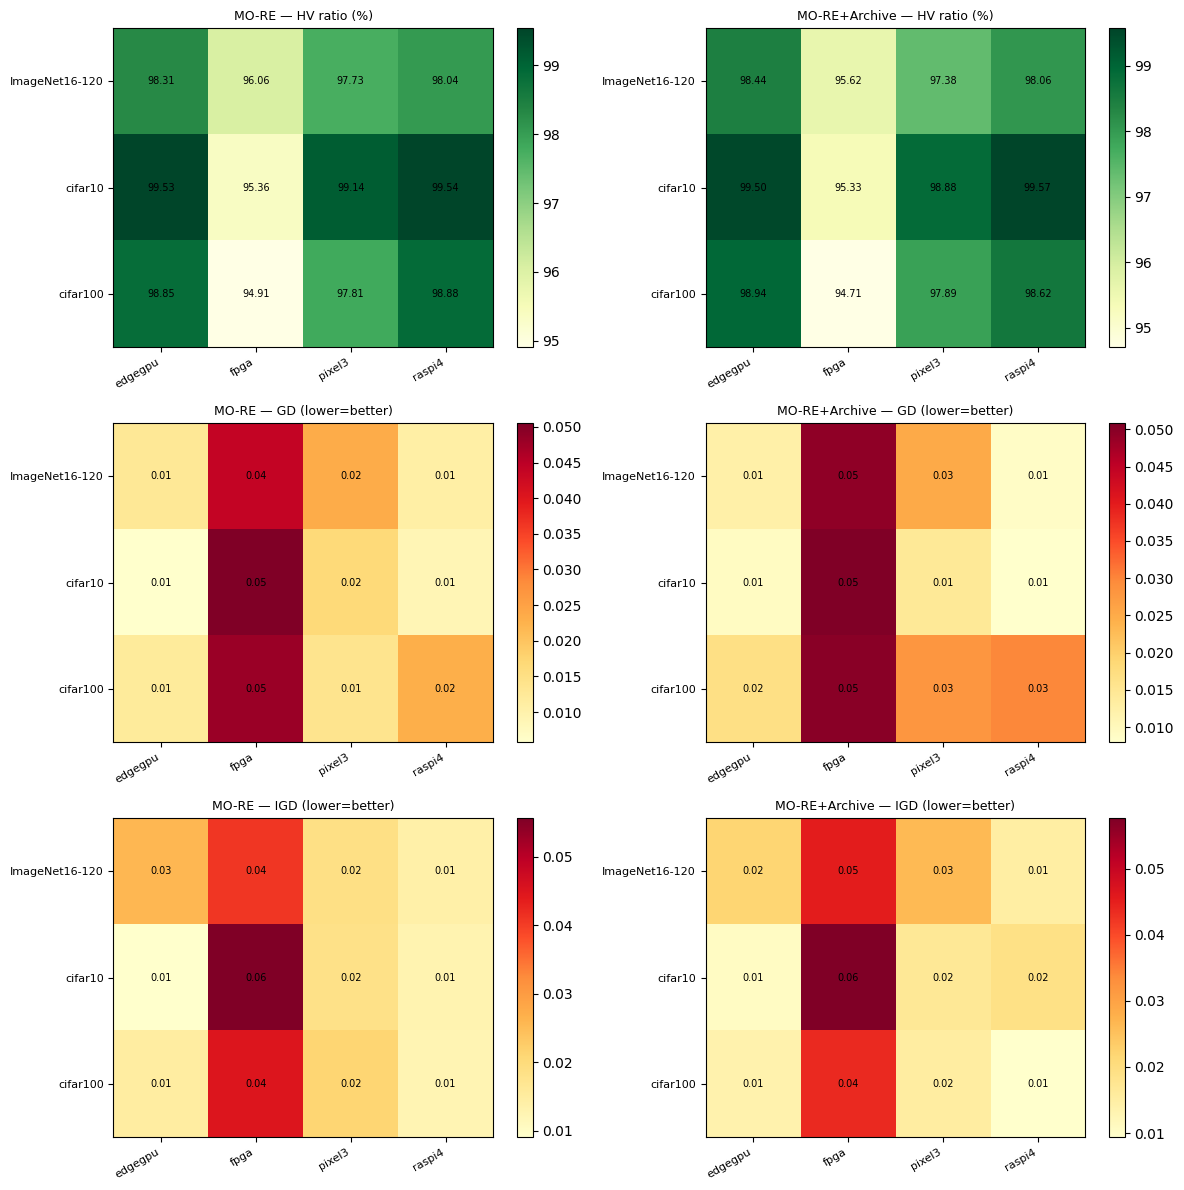

Saved: /kaggle/working/mo_re_results/summary_heatmaps.png


In [8]:
metrics_cfg = [
    ("_hv",  "HV ratio (%)",     "YlGn"),
    ("_gd",  "GD (lower=better)", "YlOrRd"),
    ("_igd", "IGD (lower=better)","YlOrRd"),
]

fig, axes = plt.subplots(len(metrics_cfg), len(col_keys),
                         figsize=(6 * len(col_keys), 4 * len(metrics_cfg)))

for row_idx, (suffix, label, cmap) in enumerate(metrics_cfg):
    for col_idx, (name, key) in enumerate(zip(variant_names, col_keys)):
        ax  = axes[row_idx][col_idx]
        col = f"{key}{suffix}"
        pivot = summary_df.pivot(index="dataset", columns="platform", values=col)
        im    = ax.imshow(pivot.values, cmap=cmap, aspect="auto")
        plt.colorbar(im, ax=ax)
        ax.set_xticks(range(len(pivot.columns)))
        ax.set_xticklabels(pivot.columns, rotation=30, ha="right", fontsize=8)
        ax.set_yticks(range(len(pivot.index)))
        ax.set_yticklabels(pivot.index, fontsize=8)
        ax.set_title(f"{name} — {label}", fontsize=9)
        for i in range(len(pivot.index)):
            for j in range(len(pivot.columns)):
                v = pivot.values[i, j]
                if not np.isnan(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            fontsize=7)

plt.tight_layout()
heatmap_path = os.path.join(OUTPUT_ROOT, "summary_heatmaps.png")
plt.savefig(heatmap_path, dpi=130, bbox_inches="tight")
plt.show()
print(f"Saved: {heatmap_path}")

## 8 · Output file listing

In [9]:
print("Output files")
print("=" * 55)
for root, dirs, files in os.walk(OUTPUT_ROOT):
    level  = root.replace(OUTPUT_ROOT, "").count(os.sep)
    indent = "  " * level
    rel    = os.path.relpath(root, OUTPUT_ROOT)
    if rel != ".":
        print(f"{indent}{rel}/")
    for fname in sorted(files):
        fpath = os.path.join(root, fname)
        size  = os.path.getsize(fpath)
        print(f"{'  ' * (level+1)}{fname}  ({size/1024:.1f} KB)")

Output files
  summary.csv  (0.8 KB)
  summary_heatmaps.png  (145.1 KB)
  cifar10/
    cifar10/cifar10/
      cifar10/cifar10/raspi4/
        comparison.png  (103.3 KB)
        mo_re_archive_front.csv  (0.9 KB)
        mo_re_front.csv  (0.9 KB)
      cifar10/cifar10/edgegpu/
        comparison.png  (109.6 KB)
        mo_re_archive_front.csv  (0.5 KB)
        mo_re_front.csv  (0.4 KB)
      cifar10/cifar10/pixel3/
        comparison.png  (105.9 KB)
        mo_re_archive_front.csv  (0.5 KB)
        mo_re_front.csv  (0.6 KB)
      cifar10/cifar10/fpga/
        comparison.png  (95.1 KB)
        mo_re_archive_front.csv  (0.3 KB)
        mo_re_front.csv  (0.3 KB)
  cifar100/
    cifar100/cifar100/
      cifar100/cifar100/raspi4/
        comparison.png  (112.9 KB)
        mo_re_archive_front.csv  (1.1 KB)
        mo_re_front.csv  (1.1 KB)
      cifar100/cifar100/edgegpu/
        comparison.png  (116.6 KB)
        mo_re_archive_front.csv  (0.8 KB)
        mo_re_front.csv  (0.8 KB)
      cifar1

In [10]:
import shutil
shutil.make_archive(
    base_name="/kaggle/working/mo_re_results",
    format="zip",
    root_dir="/kaggle/working",
    base_dir="mo_re_results"
)
print("Done. Download mo_re_results.zip from the Output tab.")

Done. Download mo_re_results.zip from the Output tab.


---
## What changed vs. base MO-RE

| Component | MO-RE | MO-RE+Archive |
|---|---|---|
| Aging population (kill oldest) | ✓ | ✓ unchanged |
| Pareto parent selection | ✓ | ✓ unchanged |
| Mutation | uniform random | uniform random unchanged |
| External archive | ✗ | ✓ stores all non-dominated solutions ever seen |
| Archive update | — | after every evaluation |
| Parent source | population only | population (prob 0.7) **or** archive (prob 0.3) |
| Output | front from history | archive directly (already non-dominated) |

The archive solves the **forgetting problem** of aging evolution:  
a strong architecture that ages out of the population is never lost —  
it stays in the archive and can be selected as a parent again.